# Julia から Wolfram Engine を呼び出す — 記号微分の結果を Julia で使う

[MathLink.jl](https://github.com/JuliaInterop/MathLink.jl) を使って Julia から Wolfram Engine を呼び出します（積分編 `julia_wolfram_integral.ipynb` の続き）。

- 導関数・高階導関数 → 結果を **Julia の関数** に変換して使う
- 微分係数 → **厳密値** を受け取り，Julia の数値として使う
- 偏微分・勾配・ヘッセ行列 → Julia の **ベクトル／行列を返す関数** にする
- テイラー展開 → Julia の多項式関数にする
- 数式は $\LaTeX$ 組版（TraditionalForm 相当）で表示する

**注意**：無料版 Wolfram Engine は同時に起動できるカーネル数に上限があります。他のノートブックや `wolframscript` が動いたままだと接続に失敗するので，使い終わったカーネルは停止してください。

## 0. 準備

共通の関数（表示 `tex`, `showtex`，変換 `to_expr`, `to_value`, `to_function` など）は `wolfram_common.jl` にまとめてあります。  
このノートブックと同じフォルダに置いて，`include` で読み込みます。初回だけパッケージを追加します（追加済みなら次のセルは実行不要）。

In [1]:
# import Pkg; Pkg.add(["MathLink", "SpecialFunctions", "Plots"])

In [2]:
include("wolfram_common.jl")      # MathLink の読み込みと，共通の関数（表示・変換）
using Plots

## 1. 基本：`D[f, x]` を `weval` で評価する

``W`...` `` の中に Wolfram 言語を書き，`weval` で評価します。結果は自動的に $\LaTeX$ で表示されます。

In [3]:
weval(W`D[x^2 Sin[x], x]`)

W`Plus[Times[Power[x, 2], Cos[x]], Times[2, x, Sin[x]]]`

In [4]:
weval(W`D[x^2 Sin[x], {x, 3}]`)      # 3 階導関数

W`Plus[Times[6, Cos[x]], Times[-1, Power[x, 2], Cos[x]], Times[-6, x, Sin[x]]]`

## 2. きれいに表示するための関数

In [5]:
# Wolfram 言語の文字列 → 評価せずに LaTeX 文字列（入力した形のまま表示する）
texheld(s::AbstractString) = heldtex(s)

# 微分演算子 d/dx, dⁿ/dxⁿ の LaTeX
dop(var, n=1; d="d") = n == 1 ? "\\frac{$d}{$d $var}" : "\\frac{$d^{$n}}{$d $var^{$n}}"

dop (generic function with 2 methods)

## 3. Wolfram の式を Julia の式・関数に変換する

変換の関数は，共通ファイル `wolfram_common.jl` にまとめてあります（0 節の `include` で読み込み済み）。

- `to_expr(w)`：Wolfram の式 → Julia の式（`Expr`）
- `to_value(w)`：Wolfram の式 → Julia の値
- `to_function(w, :x, ...)`：Wolfram の式 → Julia の関数
- 対応表 `WFUNC`（Wolfram の関数名 → Julia の関数名）に無い関数が出てきたら，`WFUNC["名前"] = :Juliaの関数名` で追加できます。

このノートブックで特に使う変換：

- 勾配などのリスト `{a, b}` → Julia のベクトル
- ヘッセ行列のような行列は，`to_matrix_function` で行列を返す関数にする

## 4. 導関数 → Julia の関数として使う

関数を Wolfram 言語の文字列で 1 回書けば，`wfun` で $f$ 自身を，`derivative` で $f'$ を Julia の関数として得られます。
`derivative` の戻り値は `(Wolfram の式, Julia の関数)` です。

In [6]:
function derivative(f::AbstractString, var::AbstractString="x"; n::Integer=1, simplify=true)
    dw = weval(MathLink.parseexpr("D[$f, {$var, $n}]"))
    simplify && (dw = weval(W"Simplify"(dw)))
    showtex(dop(var, n) * "\\left(" * texheld(f) * "\\right) = " * tex(dw))
    return dw, to_function(dw, Symbol(var))
end

derivative (generic function with 2 methods)

In [7]:
fstr = "x^2 Sin[x]"
f = wfun(fstr, :x)                 # f(x)  を Julia の関数に
dfw, df = derivative(fstr)         # f'(x) を Wolfram の式と Julia の関数に

to_expr(dfw)                       # Julia の式（Expr）に変換されたもの

:(x * (x * cos(x) + 2 * sin(x)))

In [8]:
df(1.0), df(π), df(big"1.0")       # Float64 でも BigFloat でも呼べる

(2.2232442754839328, -9.869604401089358, 2.223244275483932730705941250703574602977436542214664359015600675364921203556964)

**検算**：中心差分 $\dfrac{f(x+h)-f(x-h)}{2h}$ と比べます。

In [9]:
numdiff(f, x; h=1e-6) = (f(x + h) - f(x - h)) / 2h

for x0 in (0.5, 1.0, 2.0)
    println("x = $x0 :  Wolfram → Julia  ", df(x0), "    中心差分  ", numdiff(f, x0))
end

x = 0.5 :  Wolfram → Julia  0.6988211790767962    中心差分  0.6988211790695531
x = 1.0 :  Wolfram → Julia  2.2232442754839328    中心差分  2.2232442755121262
x = 2.0 :  Wolfram → Julia  1.9726023611141572    中心差分  1.9726023612332


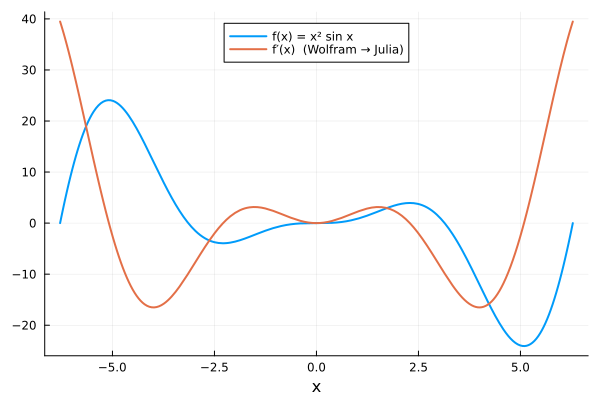

In [10]:
plot(f, -2π, 2π; label="f(x) = x² sin x", lw=2)
plot!(df, -2π, 2π; label="f′(x)  (Wolfram → Julia)", lw=2, xlabel="x", legend=:top)

### いろいろな関数

In [11]:
_, d1 = derivative("Tan[x]")
_, d2 = derivative("ArcSin[x]")
_, d3 = derivative("x^x")
_, d4 = derivative("Log[x + Sqrt[x^2 + 1]]")
_, d5 = derivative("Exp[-x^2/2]/Sqrt[2 Pi]")

d1(1.0), d2(0.5), d3(2.0), d4(1.0), d5(1.0)

(3.425518820814759, 1.1547005383792517, 6.772588722239782, 0.7071067811865475, -0.24197072451914337)

## 5. 高階導関数

`n=` で階数を指定します。Julia のループで $f, f', f'', \dots$ をまとめて作れます。

In [12]:
gstr = "Exp[-x^2]"
dg = [derivative(gstr; n=k)[2] for k in 1:4];     # 1〜4 階導関数（Julia の関数の配列）

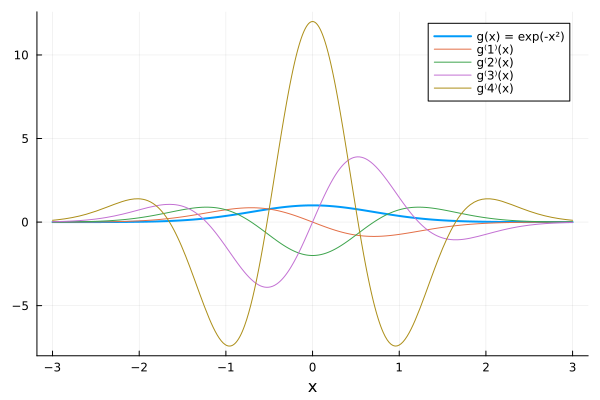

In [13]:
plot(wfun(gstr, :x), -3, 3; label="g(x) = exp(-x²)", lw=2, xlabel="x")
for k in 1:4
    plot!(dg[k], -3, 3; label="g⁽$(k)⁾(x)")
end
plot!()

## 6. 微分係数の厳密値

`式 /. x -> a` で $x=a$ を代入します。$a$ が $\pi/3$ のような厳密な数なら，微分係数も厳密な式で返ります。
`to_value` で Julia の値に直します（有理数は `Rational` のまま厳密，$\pi$ や根号を含むものは `Float64`）。

In [14]:
cw = weval(W`D[x^2 Sin[x], x] /. x -> Pi/3`)      # f′(π/3) の厳密値
showtex("f'\\!\\left(\\frac{\\pi}{3}\\right) = " * tex(cw))

@show to_expr(cw)
@show to_value(cw)
@show df(π/3);                                    # 4 節で作った Julia 関数の値と一致

to_expr(cw) = :((1 / sqrt(3)) * π + 1 // 18 * π ^ 2)
to_value(cw) = 2.3621107198502935
df(π / 3) = 2.3621107198502926


In [15]:
r = to_value(weval(W`D[x^5/(1 + x^2), x] /. x -> 2`))
@show r typeof(r);                                # 有理数は Rational として厳密

r = 272//25
typeof(r) = Rational{Int64}


In [16]:
# 高精度が欲しいときは wN（Wolfram の N[式, 桁数] → BigFloat）
wN(cw, 50)

2.362110719850293329418216646524164128690382881828348

## 7. 応用

### 7.1 接線

$x=a$ での接線 $y = f(a) + f'(a)(x-a)$ を描きます。

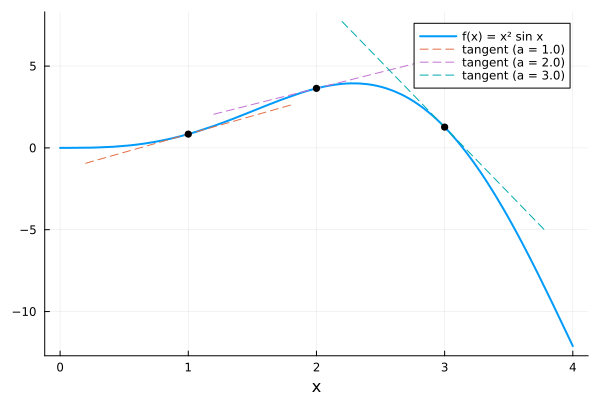

In [17]:
tangent(f, df, a) = x -> f(a) + df(a) * (x - a)

plot(f, 0, 4; label="f(x) = x² sin x", lw=2, xlabel="x")
for a in (1.0, 2.0, 3.0)
    plot!(tangent(f, df, a), a - 0.8, a + 0.8; label="tangent (a = $a)", ls=:dash)
    scatter!([a], [f(a)]; label="", color=:black)
end
plot!()

### 7.2 ニュートン法

$x_{k+1} = x_k - \dfrac{f(x_k)}{f'(x_k)}$ の $f'$ に Wolfram の導関数を使います。

In [18]:
function newton(f, df, x; tol=1e-14, maxiter=50)
    for k in 1:maxiter
        dx = f(x) / df(x)
        x -= dx
        println("k = $k :  x = $x")
        abs(dx) < tol && break
    end
    return x
end

pstr = "x^3 - 3x + 1"
p = wfun(pstr, :x)
_, dp = derivative(pstr)

root = newton(p, dp, 2.0)
@show p(root);

k = 1 :  x = 1.6666666666666667
k = 2 :  x = 1.548611111111111
k = 3 :  x = 1.5323901618653801
k = 4 :  x = 1.5320889893972243
k = 5 :  x = 1.532088886237968
k = 6 :  x = 1.532088886237956
k = 7 :  x = 1.532088886237956
p(root) = -4.440892098500626e-16


### 7.3 極値

$f'(x)=0$ を Wolfram の `Solve` で厳密に解き，解を Julia の配列として受け取ります。
2 階導関数の符号で極大・極小を判定します。

In [19]:
critw = weval(W`x /. Solve[D[x^3 - 3x + 1, x] == 0, x]`)     # f′(x) = 0 の厳密解のリスト
showtex("f'(x) = 0 \\iff x \\in " * tex(critw))

crit = to_value(critw)                                       # Julia の配列

2-element Vector{Int64}:
 -1
  1

x = -1 :  f(x) = 3,  f″(x) = -6  →  極大
x = 1 :  f(x) = -1,  f″(x) = 6  →  極小


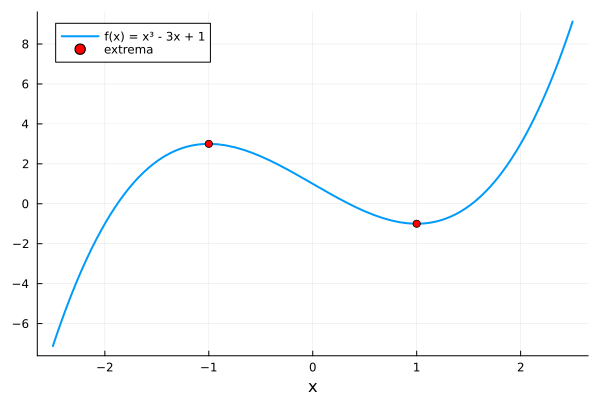

In [20]:
_, d2p = derivative(pstr; n=2)

for c in crit
    println("x = $c :  f(x) = ", p(c), ",  f″(x) = ", d2p(c), "  →  ", d2p(c) < 0 ? "極大" : "極小")
end

plot(p, -2.5, 2.5; label="f(x) = x³ - 3x + 1", lw=2, xlabel="x")
scatter!(crit, p.(crit); label="extrema", color=:red)

## 8. 偏微分・勾配・ヘッセ行列

- `D[f, x, y]`：$x$ で微分してから $y$ で微分
- `D[f, {{x, y}}]`：勾配 $\nabla f$（リスト → Julia の**ベクトル**を返す関数）
- `D[f, {{x, y}, 2}]`：ヘッセ行列（リストのリスト → Julia の**行列**を返す関数）

In [21]:
hstr = "x^2 Sin[y] + y^3"
h = wfun(hstr, :x, :y)

hxw = weval(MathLink.parseexpr("D[$hstr, x]"))
hyw = weval(MathLink.parseexpr("D[$hstr, y]"))
showtex(dop("x"; d="\\partial") * "\\left(" * texheld(hstr) * "\\right) = " * tex(hxw))
showtex(dop("y"; d="\\partial") * "\\left(" * texheld(hstr) * "\\right) = " * tex(hyw))

In [22]:
gradw = weval(MathLink.parseexpr("D[$hstr, {{x, y}}]"))
hessw = weval(MathLink.parseexpr("D[$hstr, {{x, y}, 2}]"))
showtex("\\nabla f = " * tex(W"MatrixForm"(gradw)) * ",\\qquad H = " * tex(W"MatrixForm"(hessw)))

∇h = to_function(gradw, :x, :y)      # (x, y) -> ベクトル
Hh = to_matrix_function(hessw, :x, :y)   # (x, y) -> 行列
to_expr(hessw)

:([[2 * sin(y), 2 * x * cos(y)], [2 * x * cos(y), 6y + -1 * x ^ 2 * sin(y)]])

In [23]:
@show ∇h(1.0, 2.0)
Hh(1.0, 2.0)

∇h(1.0, 2.0) = [1.8185948536513634, 11.583853163452858]


2×2 Matrix{Float64}:
  1.81859   -0.832294
 -0.832294  11.0907

In [24]:
# 検算：勾配を中心差分と比べる
x0, y0 = 1.0, 2.0
@show ∇h(x0, y0)
@show [numdiff(x -> h(x, y0), x0), numdiff(y -> h(x0, y), y0)];

∇h(x0, y0) = [1.8185948536513634, 11.583853163452858]
[numdiff((x->begin
                #= In[24]:4 =#
                h(x, y0)
            end), x0), numdiff((y->begin
                #= In[24]:4 =#
                h(x0, y)
            end), y0)] = [1.8185948533755436, 11.583853163799063]


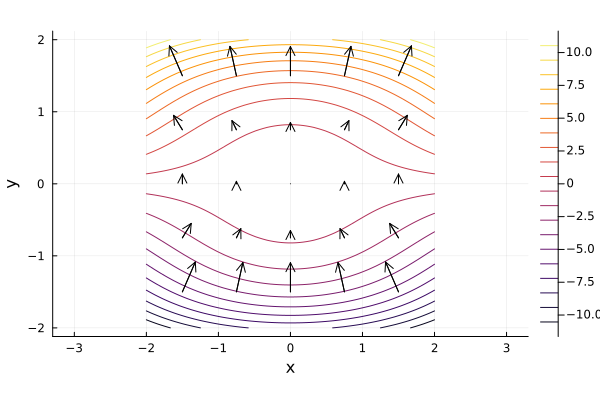

In [25]:
# 等高線と勾配ベクトル（勾配は等高線に直交する）
xs = range(-2, 2; length=80); ys = range(-2, 2; length=80)
contour(xs, ys, (x, y) -> h(x, y); levels=20, xlabel="x", ylabel="y", aspect_ratio=1)

pts = [(x, y) for x in -1.5:0.75:1.5 for y in -1.5:0.75:1.5]
gs  = [0.06 .* ∇h(x, y) for (x, y) in pts]
quiver!(first.(pts), last.(pts); quiver=(first.(gs), last.(gs)), color=:black)

## 9. テイラー展開

`Series[f, {x, a, n}]` は $O(x^{n+1})$ つきの級数，`Normal[...]` で多項式部分だけを取り出します。
多項式を Julia の関数にして，元の関数と比べます。

In [26]:
showtex(texheld("Exp[x] Sin[x]") * " = " * tex(weval(W`Series[Exp[x] Sin[x], {x, 0, 6}]`)))

In [27]:
orders = [1, 3, 5, 7, 9]
taylor = [to_function(weval(W`Normal[Series[Sin[x], {x, 0, $n}]]`), :x) for n in orders];

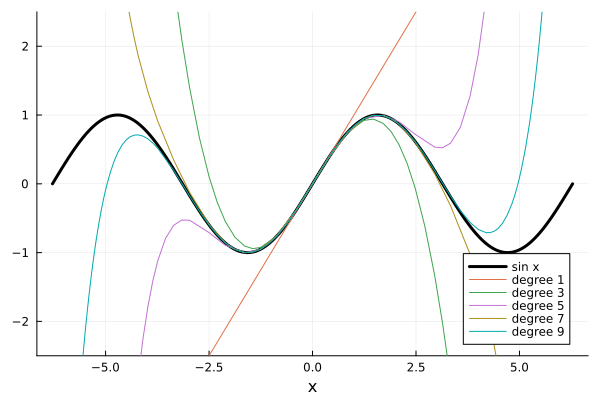

In [28]:
plot(sin, -2π, 2π; label="sin x", lw=3, color=:black, ylims=(-2.5, 2.5), xlabel="x")
for (n, T) in zip(orders, taylor)
    plot!(T, -2π, 2π; label="degree $n")
end
plot!()

## 10. うまくいかないとき

- **接続エラー（`AssertionError: nextpacket(...)` など）**：Wolfram Engine のカーネル数上限に達しています。他のノートブックのカーネルや `wolframscript` を止めてから，Julia カーネルを再起動してください。
- **未対応の関数が出た**：エラーメッセージに出た名前を `WFUNC` に追加します（例：`"BesselJ" => :besselj`）。
- **未定義の関数を微分した**：`D[f[x], x]` は `f'[x]` のまま返り，Julia の関数にはできません（`to_expr` がエラーで知らせます）。
- **結果が複雑すぎる**：`derivative` は既定で `Simplify` をかけています。`simplify=false` で生の結果，Wolfram 側で `FullSimplify` や `Factor` を使うこともできます。
- **LaTeX 表示を止めたい**：`MathLink.set_texOutput(false)`

In [29]:
# 未対応の関数が出る例：ベッセル関数
bw = weval(W`D[BesselJ[0, x], x]`)
showtex(dop("x") * "J_0(x) = " * tex(bw))
try
    to_function(bw, :x)
catch e
    println(e.msg)
end

未対応の Wolfram 関数 BesselJ です。WFUNC["BesselJ"] = :Juliaの関数名 で対応を追加してください。


In [30]:
# 対応表に 1 行追加すれば変換できる（besselj は SpecialFunctions の関数）
WFUNC["BesselJ"] = :besselj
dJ0 = to_function(bw, :x)

#to_function##0 (generic function with 1 method)

In [31]:
dJ0(1.0), -besselj(1, 1.0)

(-0.4400505857449335, -0.4400505857449335)